# Prediksi US AQI Jakarta (AQI Hari Berikutnya)

**Tujuan:** memprediksi US AQI *hari berikutnya* dari kondisi polutan hari ini dan riwayat beberapa hari terakhir.

**Data:** Kaggle "Air Quality Dataset for Jakarta" (nitirajkulkarni, lisensi CC0). Harian, 2022-08-01 sampai 2026-02-18. Nilainya berasal dari model CAMS lewat Open-Meteo, **bukan** sensor stasiun.

**Alur:** load data, pembersihan, validasi logika, outlier, EDA, fitur lag dan split berdasarkan waktu, normalisasi, perbandingan model dengan baseline, tuning, model final, feature importance, simpan model, prediksi, analisis kesalahan.

**Cara menjalankan:** *Runtime, lalu Restart session and run all*. Upload file zip dataset saat diminta pada langkah 2.

## 1. Import Library

In [ ]:
import json
import joblib
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.preprocessing import RobustScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit, cross_val_score
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor

## 2. Load Data

In [ ]:
from google.colab import files

uploaded = files.upload()          # pilih file .zip dari komputermu
nama_zip = list(uploaded.keys())[0]
print("terupload:", nama_zip)

Saving jakarta-id-1642911.zip to jakarta-id-1642911 (1).zip
terupload: jakarta-id-1642911 (1).zip


In [ ]:
import zipfile, os

FOLDER = "/content/aqi_jakarta"
os.makedirs(FOLDER, exist_ok=True)

with zipfile.ZipFile(nama_zip) as z:
    print(z.namelist())            # lihat isi zip dulu
    z.extractall(FOLDER)

for root, _, fs in os.walk(FOLDER):
    for f in fs:
        print(os.path.join(root, f))

['air_quality_historical.csv', 'city_info.csv', 'dataset-metadata.json', 'data_dictionary.csv', 'README.md']
/content/aqi_jakarta/city_info.csv
/content/aqi_jakarta/README.md
/content/aqi_jakarta/air_quality_historical.csv
/content/aqi_jakarta/dataset-metadata.json
/content/aqi_jakarta/data_dictionary.csv


In [ ]:
city  = pd.read_csv(f"{FOLDER}/city_info.csv")
kamus = pd.read_csv(f"{FOLDER}/data_dictionary.csv")
aq    = pd.read_csv(f"{FOLDER}/air_quality_historical.csv")

with open(f"{FOLDER}/dataset-metadata.json") as f:
    meta = json.load(f)

print(aq.shape)
aq.head()

(1298, 12)


,date,pm10,pm2_5,carbon_monoxide,nitrogen_dioxide,sulphur_dioxide,ozone,aerosol_optical_depth,dust,uv_index,us_aqi,european_aqi
0,2022-08-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2022-08-02,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2022-08-03,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2022-08-04,120.764706,83.923529,2635.176471,82.235294,23.894118,186.235294,1.228824,0.0,1.473529,NaN,NaN
4,2022-08-05,118.725000,82.300000,3027.375000,96.512500,24.420833,118.583333,1.030417,0.0,1.127083,187.588235,109.588235


In [ ]:
aq.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1298 entries, 0 to 1297
Data columns (total 12 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   date                   1298 non-null   object 
 1   pm10                   1295 non-null   float64
 2   pm2_5                  1295 non-null   float64
 3   carbon_monoxide        1295 non-null   float64
 4   nitrogen_dioxide       1295 non-null   float64
 5   sulphur_dioxide        1295 non-null   float64
 6   ozone                  1295 non-null   float64
 7   aerosol_optical_depth  1295 non-null   float64
 8   dust                   1295 non-null   float64
 9   uv_index               1295 non-null   float64
 10  us_aqi                 1294 non-null   float64
 11  european_aqi           1294 non-null   float64
dtypes: float64(11), object(1)
memory usage: 121.8+ KB


## 3. Missing Values

In [ ]:
aq.isnull().sum()

,0
date,0
pm10,3
pm2_5,3
carbon_monoxide,3
nitrogen_dioxide,3
sulphur_dioxide,3
ozone,3
aerosol_optical_depth,3
dust,3
uv_index,3


In [ ]:
aq = aq.dropna(subset=['us_aqi'])

print(aq.shape)
print(aq.isna().sum().sum())

(1294, 12)
0


In [ ]:
aq.isnull().sum()

,0
date,0
pm10,0
pm2_5,0
carbon_monoxide,0
nitrogen_dioxide,0
sulphur_dioxide,0
ozone,0
aerosol_optical_depth,0
dust,0
uv_index,0


## 4. Metadata Kota dan Kamus Data

File `city_info.csv` (1 baris) dan `data_dictionary.csv` hanya untuk dibaca, tidak dipakai sebagai fitur.

In [ ]:
print(city.T)
print(kamus[['column', 'unit', 'description']])

                      0
geoname_id      1642911
city_name       Jakarta
country_code         ID
admin1                4
admin2              NaN
feature_code       PPLC
latitude       -6.21462
longitude     106.84513
population      8540121
                   column        unit                  description
0              geoname_id         NaN  GeoNames unique identifier.
1               city_name         NaN     City name from GeoNames.
2            country_code         NaN            ISO country code.
3                  admin1         NaN        First admin division.
4                  admin2         NaN       Second admin division.
5            feature_code         NaN       GeoNames feature code.
6                latitude     degrees    Latitude decimal degrees.
7               longitude     degrees   Longitude decimal degrees.
8              population      people    Population from GeoNames.
9                    date  YYYY-MM-DD                  Time index.
10                  pm2

## 5. Tipe Data dan Index Tanggal

In [ ]:
aq['date'] = pd.to_datetime(aq['date'])
aq = aq.set_index('date').sort_index()

print(aq.shape)
print(aq.index.min().date(), "sampai", aq.index.max().date())
aq.describe().T

(1294, 11)
2022-08-05 sampai 2026-02-18


,count,mean,std,min,25%,50%,75%,max
pm10,1294.0,82.950609,33.102482,0.920833,57.839583,85.366667,105.955208,196.954167
pm2_5,1294.0,64.856772,24.903465,0.641667,47.503125,65.862500,81.408333,150.091667
carbon_monoxide,1294.0,2302.981163,946.630404,59.333333,1643.395833,2112.750000,2862.343750,6181.041667
nitrogen_dioxide,1294.0,62.831247,23.494026,0.000000,47.608333,59.337500,75.758333,158.991667
sulphur_dioxide,1294.0,38.117790,15.800615,0.479167,25.323958,42.089583,49.564583,79.575000
ozone,1294.0,71.894771,34.597651,9.625000,38.062500,79.812500,99.604167,161.958333
aerosol_optical_depth,1294.0,0.723280,0.373043,0.035417,0.429688,0.696875,0.975937,2.149167
dust,1294.0,0.028690,0.182161,0.000000,0.000000,0.000000,0.000000,3.833333
uv_index,1294.0,1.588761,0.431211,0.379167,1.279167,1.568750,1.897396,3.091667
us_aqi,1294.0,147.902503,34.977798,13.750000,132.343750,160.145833,172.083333,203.000000


In [ ]:
aq.columns

Index(['pm10', 'pm2_5', 'carbon_monoxide', 'nitrogen_dioxide',
       'sulphur_dioxide', 'ozone', 'aerosol_optical_depth', 'dust', 'uv_index',
       'us_aqi', 'european_aqi'],
      dtype='object')

In [ ]:
aq.dtypes

,0
pm10,float64
pm2_5,float64
carbon_monoxide,float64
nitrogen_dioxide,float64
sulphur_dioxide,float64
ozone,float64
aerosol_optical_depth,float64
dust,float64
uv_index,float64
us_aqi,float64


## 6. Cek Whitespace

In [ ]:
for k in aq.columns:
    if k != k.strip():
        print(f"ada spasi: {k!r}")

print(aq.columns.tolist())

['pm10', 'pm2_5', 'carbon_monoxide', 'nitrogen_dioxide', 'sulphur_dioxide', 'ozone', 'aerosol_optical_depth', 'dust', 'uv_index', 'us_aqi', 'european_aqi']


In [ ]:
kolom_teks = aq.select_dtypes(include=['object', 'string']).columns
print("kolom teks:", kolom_teks.tolist())

for k in kolom_teks:
    s = aq[k].astype(str)
    jumlah = (s != s.str.strip()).sum()
    print(f"{k}: {jumlah} nilai punya spasi di awal/akhir")

kolom teks: []


## 7. Cek Duplikat

In [ ]:
dup_tgl = aq.index.duplicated().sum()
print("tanggal duplikat:", dup_tgl)

if dup_tgl > 0:
    print(aq[aq.index.duplicated(keep=False)])

tanggal duplikat: 0


In [ ]:
dup_baris = aq.duplicated().sum()
print("baris duplikat penuh:", dup_baris)

baris duplikat penuh: 0


Jika ada tanggal duplikat, simpan yang pertama (jalankan sel ini hanya bila hasil di atas lebih dari 0; aman dijalankan kalau 0).

In [ ]:
aq = aq[~aq.index.duplicated(keep='first')]

print(aq.shape)

(1294, 11)


## 8. Tanggal Hilang dan Urutan

In [ ]:
print("urut naik:", aq.index.is_monotonic_increasing)

semua_tgl = pd.date_range(aq.index.min(), aq.index.max(), freq='D')
hilang = semua_tgl.difference(aq.index)
print("tanggal hilang:", len(hilang))

urut naik: True
tanggal hilang: 0


## 9. Validasi Logika

US AQI harus berada di rentang 0 sampai 500 dan tidak boleh negatif. Polutan juga tidak boleh negatif.

In [ ]:
print("min:", aq['us_aqi'].min(), "| max:", aq['us_aqi'].max())
print("semua di 0-500:", aq['us_aqi'].between(0, 500).all())
print("jumlah negatif:", (aq['us_aqi'] < 0).sum())

min: 13.75 | max: 203.0
semua di 0-500: True
jumlah negatif: 0


In [ ]:
print(aq[['us_aqi', 'pm2_5', 'pm10', 'ozone', 'nitrogen_dioxide']].corr()['us_aqi'].round(3))

# Hari dengan AQI terendah dan tertinggi, lihat polutannya masuk akal atau tidak
print(aq.nsmallest(5, 'us_aqi')[['us_aqi', 'pm2_5', 'pm10']])
print(aq.nlargest(5, 'us_aqi')[['us_aqi', 'pm2_5', 'pm10']])

us_aqi              1.000
pm2_5               0.884
pm10                0.860
ozone               0.775
nitrogen_dioxide    0.608
Name: us_aqi, dtype: float64
               us_aqi      pm2_5       pm10
date                                       
2022-12-15  13.750000   0.641667   0.920833
2022-12-14  32.041667   0.712500   1.033333
2022-12-29  45.375000  11.512500  16.795833
2023-01-01  46.083333  13.666667  19.933333
2023-01-25  47.583333  12.887500  18.654167
                us_aqi       pm2_5        pm10
date                                          
2023-06-06  203.000000  136.591667  196.954167
2025-08-26  199.375000  114.208333  114.658333
2023-05-23  199.083333  127.095833  182.608333
2023-07-27  199.083333  111.820833  160.600000
2022-12-07  198.541667   77.729167  112.366667


## 10. Imputasi Dua Hari Anomali

Pada **2022-12-14** dan **2022-12-15**, NO2 bernilai persis 0, sedangkan CO, SO2, dan PM turun sekitar 97 sampai 100% dari median dalam dua hari. Penurunan sebesar itu pada kota berpenduduk 8,5 juta orang tidak lazim, dan lebih mirip gangguan pada data model CAMS daripada hujan lebat (dugaan, belum diverifikasi ke sumber).

Karena hanya 2 dari 1.294 hari, keduanya diperlakukan sebagai data hilang lalu diinterpolasi berdasarkan waktu. Urutan hari tetap utuh sehingga fitur lag tidak bergeser. Nilai hasil interpolasi **bukan data nyata** dan disebut di bagian keterbatasan.

In [ ]:
tgl_anomali = ['2022-12-14', '2022-12-15']   # NO2 = 0 dan CO sangat rendah, kemungkinan artefak data model
kolom_ganti = [k for k in ['us_aqi', 'pm2_5', 'pm10', 'ozone', 'nitrogen_dioxide',
                           'sulphur_dioxide', 'carbon_monoxide',
                           'aerosol_optical_depth', 'dust', 'uv_index']
               if k in aq.columns]

aq.loc[tgl_anomali, kolom_ganti] = np.nan
aq[kolom_ganti] = aq[kolom_ganti].interpolate(method='time')

print(aq.loc['2022-12-13':'2022-12-16', ['us_aqi', 'pm2_5', 'nitrogen_dioxide']])
print("kosong:", aq.isna().sum().sum())   # harus 0

            us_aqi      pm2_5  nitrogen_dioxide
date                                           
2022-12-13  77.625  18.658333         33.083333
2022-12-14  67.625  21.663889         37.602778
2022-12-15  57.625  24.669444         42.122222
2022-12-16  47.625  27.675000         46.641667
kosong: 0


## 11. Outlier (IQR)

Outlier hanya dilihat dan dicatat, tidak dibuang. Hari dengan polusi sangat tinggi atau udara sangat bersih adalah kondisi nyata yang perlu dikenali model.

In [ ]:
Q1 = aq['us_aqi'].quantile(0.25)
Q3 = aq['us_aqi'].quantile(0.75)
IQR = Q3 - Q1

batas_bawah = Q1 - 1.5 * IQR
batas_atas  = Q3 + 1.5 * IQR
print(f"Q1={Q1:.1f}  Q3={Q3:.1f}  IQR={IQR:.1f}")
print(f"batas: {batas_bawah:.1f} sampai {batas_atas:.1f}")

outlier = aq[(aq['us_aqi'] < batas_bawah) | (aq['us_aqi'] > batas_atas)]
print("jumlah outlier:", len(outlier))
print(outlier[['us_aqi', 'pm2_5', 'pm10']].sort_values('us_aqi'))

Q1=132.3  Q3=172.1  IQR=39.7
batas: 72.7 sampai 231.7
jumlah outlier: 69
               us_aqi      pm2_5       pm10
date                                       
2022-12-29  45.375000  11.512500  16.795833
2023-01-01  46.083333  13.666667  19.933333
2023-01-25  47.583333  12.887500  18.654167
2022-12-16  47.625000  27.675000  40.800000
2022-12-30  49.666667  14.216667  20.666667
...               ...        ...        ...
2024-12-14  71.666667  19.029167  19.816667
2024-12-13  71.708333  27.429167  29.070833
2025-02-06  71.833333  36.733333  37.104167
2023-04-13  72.291667  25.945833  37.458333
2022-11-21  72.625000  24.462500  35.691667

[69 rows x 3 columns]


In [ ]:
kolom_polutan = ['pm10', 'pm2_5', 'carbon_monoxide', 'nitrogen_dioxide',
                 'sulphur_dioxide', 'ozone']

for k in kolom_polutan:
    q1, q3 = aq[k].quantile([0.25, 0.75])
    iqr_k = q3 - q1
    rendah = (aq[k] < q1 - 1.5 * iqr_k).sum()
    tinggi = (aq[k] > q3 + 1.5 * iqr_k).sum()
    print(f"{k:18s} rendah: {rendah:3d} | tinggi: {tinggi:3d}")

pm10               rendah:   0 | tinggi:   2
pm2_5              rendah:   0 | tinggi:   5
carbon_monoxide    rendah:   0 | tinggi:  27
nitrogen_dioxide   rendah:   0 | tinggi:  33
sulphur_dioxide    rendah:   0 | tinggi:   0
ozone              rendah:   0 | tinggi:   0


## 12. Filter dan Sort

`european_aqi` dibuang karena diturunkan dari polutan yang sama dengan `us_aqi` (bocor bila dipakai sebagai fitur). `dust` dibuang karena hampir seluruh nilainya nol.

In [ ]:
aq = aq.sort_index()

print("urut naik:", aq.index.is_monotonic_increasing)
print("tanggal unik:", aq.index.is_unique)
aq.head()

urut naik: True
tanggal unik: True


,pm10,pm2_5,carbon_monoxide,nitrogen_dioxide,sulphur_dioxide,ozone,aerosol_optical_depth,dust,uv_index,us_aqi,european_aqi
date,,,,,,,,,,,
2022-08-05,118.725000,82.300000,3027.375000,96.512500,24.420833,118.583333,1.030417,0.0,1.127083,187.588235,109.588235
2022-08-06,134.883333,93.520833,3394.375000,113.916667,21.829167,124.625000,1.111667,0.0,1.160417,184.083333,106.833333
2022-08-07,144.145833,99.958333,4046.958333,124.112500,19.266667,105.750000,0.995000,0.0,1.506250,184.000000,121.458333
2022-08-08,93.516667,65.162500,3171.833333,112.983333,17.733333,49.041667,0.650000,0.0,2.060417,162.750000,103.791667
2022-08-09,131.416667,90.675000,3124.833333,110.279167,25.158333,108.250000,0.936250,0.0,1.614583,173.791667,102.708333


In [ ]:
# dust: cek dulu seberapa banyak nilainya nol
print("proporsi dust = 0:", (aq['dust'] == 0).mean().round(3))

kolom_buang = ['european_aqi', 'dust']
aq = aq.drop(columns=kolom_buang, errors='ignore')

print(aq.columns.tolist())
print(aq.shape)

proporsi dust = 0: 0.944
['pm10', 'pm2_5', 'carbon_monoxide', 'nitrogen_dioxide', 'sulphur_dioxide', 'ozone', 'aerosol_optical_depth', 'uv_index', 'us_aqi']
(1294, 9)


In [ ]:
fitur = ['pm10', 'pm2_5', 'carbon_monoxide', 'nitrogen_dioxide',
         'sulphur_dioxide', 'ozone', 'aerosol_optical_depth', 'uv_index']
aq = aq[fitur + ['us_aqi']]

aq.head()

,pm10,pm2_5,carbon_monoxide,nitrogen_dioxide,sulphur_dioxide,ozone,aerosol_optical_depth,uv_index,us_aqi
date,,,,,,,,,
2022-08-05,118.725000,82.300000,3027.375000,96.512500,24.420833,118.583333,1.030417,1.127083,187.588235
2022-08-06,134.883333,93.520833,3394.375000,113.916667,21.829167,124.625000,1.111667,1.160417,184.083333
2022-08-07,144.145833,99.958333,4046.958333,124.112500,19.266667,105.750000,0.995000,1.506250,184.000000
2022-08-08,93.516667,65.162500,3171.833333,112.983333,17.733333,49.041667,0.650000,2.060417,162.750000
2022-08-09,131.416667,90.675000,3124.833333,110.279167,25.158333,108.250000,0.936250,1.614583,173.791667


In [ ]:
print(aq.shape)
print(aq.index.min().date(), "sampai", aq.index.max().date())
print("kosong:", aq.isna().sum().sum())
print("urut naik:", aq.index.is_monotonic_increasing)
aq.dtypes

(1294, 9)
2022-08-05 sampai 2026-02-18
kosong: 0
urut naik: True


,0
pm10,float64
pm2_5,float64
carbon_monoxide,float64
nitrogen_dioxide,float64
sulphur_dioxide,float64
ozone,float64
aerosol_optical_depth,float64
uv_index,float64
us_aqi,float64


## 13. EDA (Eksplorasi Data)

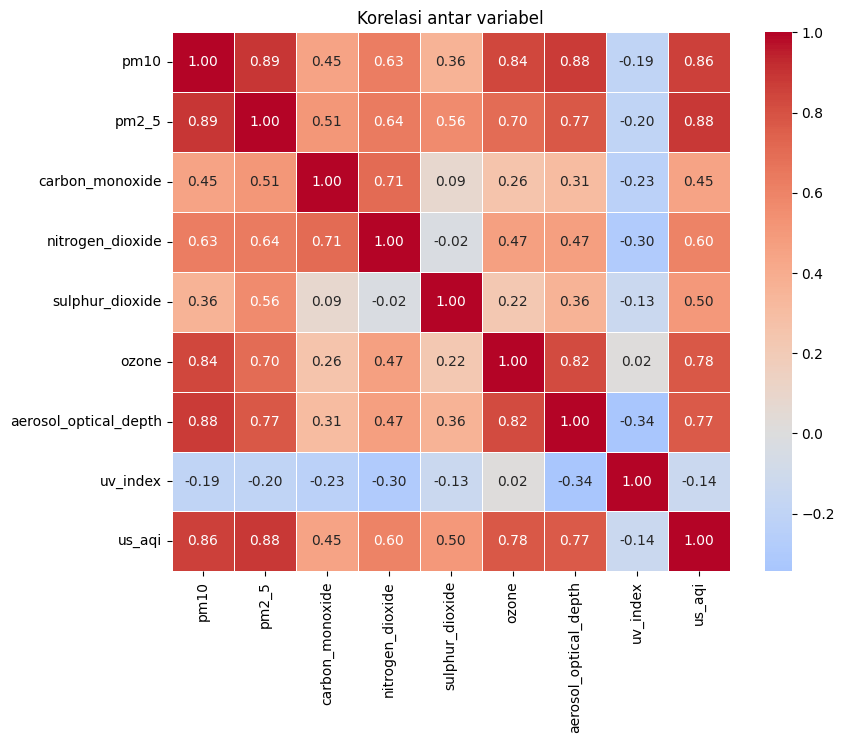

In [ ]:
# 1. Heatmap korelasi
plt.figure(figsize=(9, 7))
sns.heatmap(aq.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, linewidths=0.5)
plt.title("Korelasi antar variabel")
plt.show()

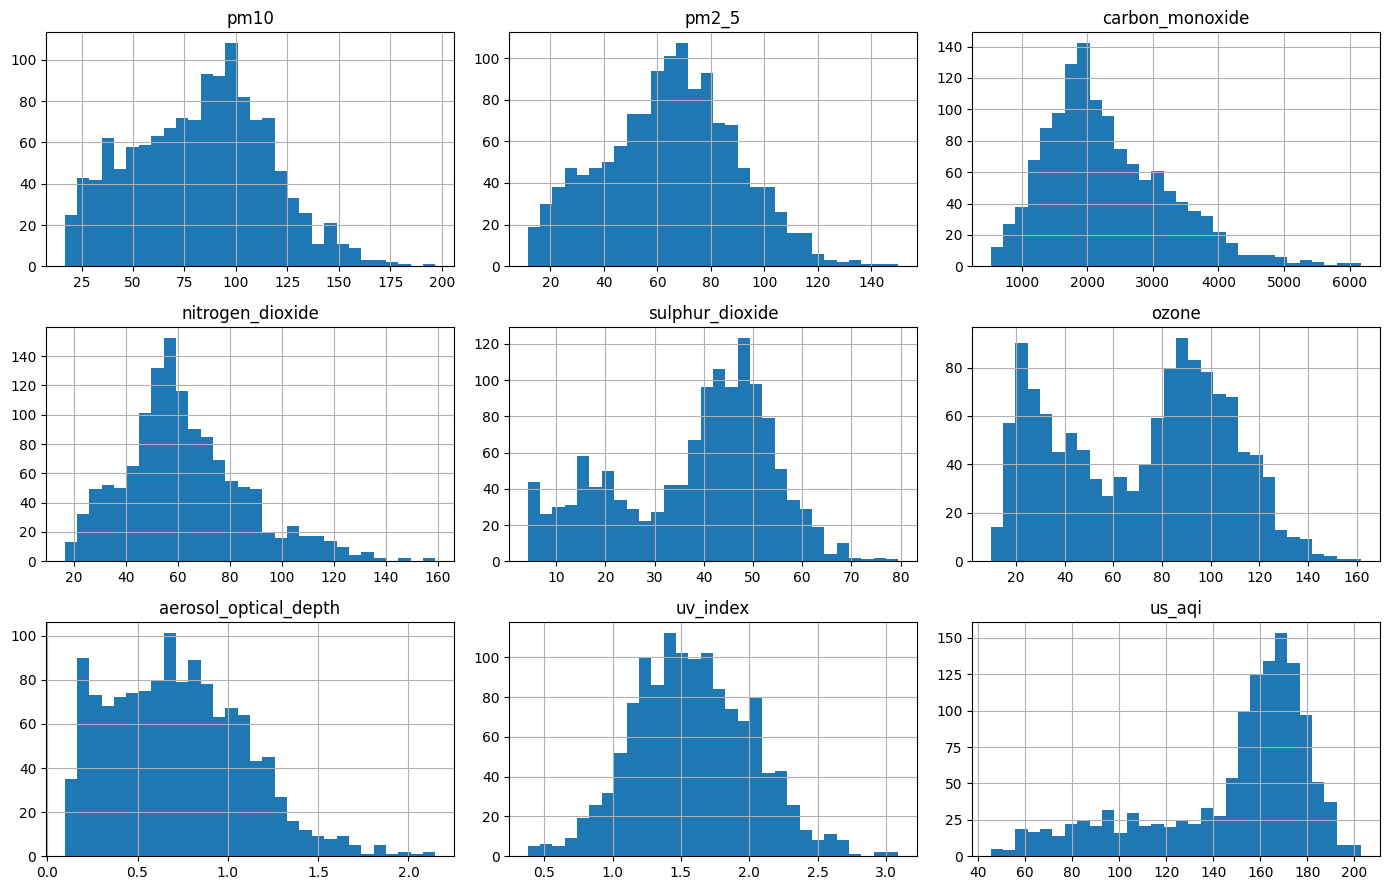

In [ ]:
# 2. Distribusi tiap variabel
aq.hist(bins=30, figsize=(14, 9))
plt.tight_layout()
plt.show()

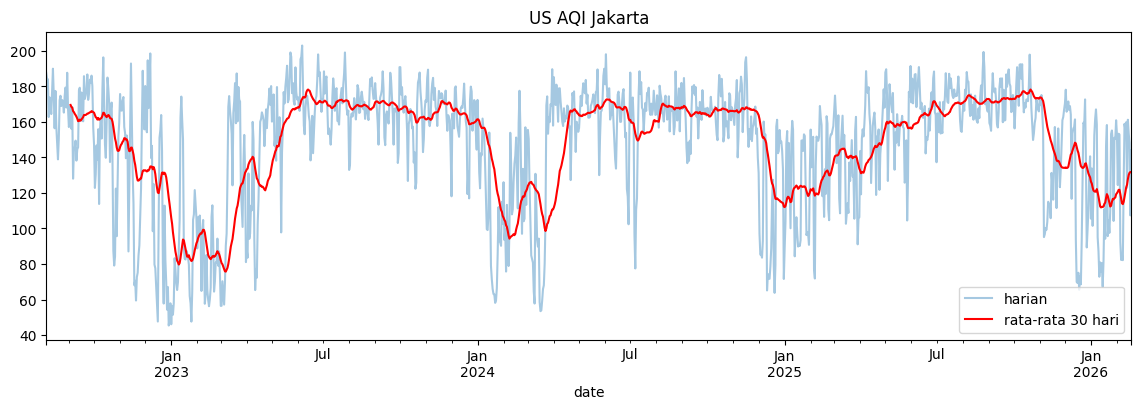

In [ ]:
# 3. Tren AQI dari waktu ke waktu
fig, ax = plt.subplots(figsize=(14, 4))
aq['us_aqi'].plot(ax=ax, alpha=0.4, label='harian')
aq['us_aqi'].rolling(30).mean().plot(ax=ax, color='red', label='rata-rata 30 hari')
ax.set_title("US AQI Jakarta")
ax.legend()
plt.show()

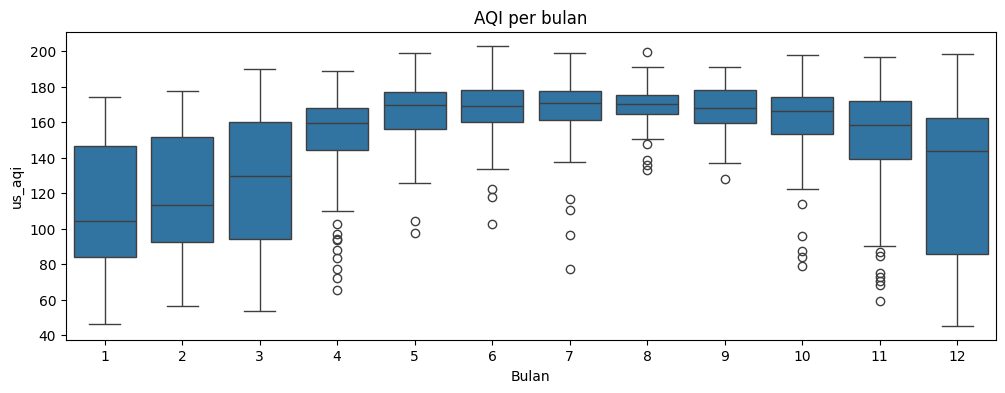

In [ ]:
# 4. Pola musiman per bulan
plt.figure(figsize=(12, 4))
sns.boxplot(x=aq.index.month, y=aq['us_aqi'])
plt.xlabel("Bulan")
plt.title("AQI per bulan")
plt.show()

In [ ]:
# 5. Seberapa mirip hari ini dengan hari-hari sebelumnya
for lag in [1, 2, 3, 7, 14]:
    print(f"autokorelasi lag {lag}: {aq['us_aqi'].autocorr(lag=lag):.3f}")

autokorelasi lag 1: 0.855
autokorelasi lag 2: 0.726
autokorelasi lag 3: 0.637
autokorelasi lag 7: 0.493
autokorelasi lag 14: 0.403


## 14. Target, Fitur Lag, dan Split

Target adalah US AQI **besok** (`shift(-1)`). Split berdasarkan waktu (80% awal untuk latih, 20% akhir untuk uji), bukan acak, supaya model tidak "melihat masa depan".

In [ ]:
data = aq.copy()

# Target: AQI hari berikutnya
data['target_aqi'] = data['us_aqi'].shift(-1)

# Fitur lag dan rata-rata bergulir
for lag in [1, 2, 3, 7]:
    data[f'aqi_lag{lag}']  = data['us_aqi'].shift(lag)
    data[f'pm25_lag{lag}'] = data['pm2_5'].shift(lag)
data['aqi_rata7'] = data['us_aqi'].rolling(7).mean()

# Fitur musiman melingkar
bulan = data.index.month
data['bulan_sin'] = np.sin(2 * np.pi * bulan / 12)
data['bulan_cos'] = np.cos(2 * np.pi * bulan / 12)

data = data.dropna()

# Pisahkan X, y dan split berdasarkan waktu (bukan acak)
X = data.drop(columns=['target_aqi'])
y = data['target_aqi']

i = int(len(data) * 0.8)
X_train, X_test = X.iloc[:i], X.iloc[i:]
y_train, y_test = y.iloc[:i], y.iloc[i:]

print("train:", X_train.shape, X_train.index.min().date(), "-", X_train.index.max().date())
print("test :", X_test.shape,  X_test.index.min().date(),  "-", X_test.index.max().date())

train: (1028, 20) 2022-08-12 - 2025-06-04
test : (258, 20) 2025-06-05 - 2026-02-17


## 15. Normalisasi

`RobustScaler` (median dan IQR) dipilih karena fitur punya outlier di sisi tinggi. Scaler di-`fit` **hanya** pada data latih. Hanya Linear Regression yang memakai data ini; Random Forest dan XGBoost memakai data asli.

In [ ]:
scaler = RobustScaler()

# fit HANYA di data latih, test hanya di-transform
X_train_s = pd.DataFrame(scaler.fit_transform(X_train),
                         columns=X_train.columns, index=X_train.index)
X_test_s  = pd.DataFrame(scaler.transform(X_test),
                         columns=X_test.columns, index=X_test.index)

# Bandingkan skala sebelum dan sesudah
print("SEBELUM (median, IQR):")
print(pd.DataFrame({'median': X_train.median(),
                    'IQR': X_train.quantile(.75) - X_train.quantile(.25)}).round(2))

print("\nSESUDAH (median harus ~0):")
print(X_train_s.describe().T[['50%', 'std', 'min', 'max']].round(2))

SEBELUM (median, IQR):
                        median      IQR
pm10                     87.17    51.27
pm2_5                    63.32    31.16
carbon_monoxide        2098.06  1166.06
nitrogen_dioxide         57.86    26.31
sulphur_dioxide          40.60    27.70
ozone                    83.00    62.09
aerosol_optical_depth     0.73     0.58
uv_index                  1.56     0.60
us_aqi                  159.15    42.96
aqi_lag1                159.15    42.90
pm25_lag1                63.32    31.14
aqi_lag2                159.15    42.90
pm25_lag2                63.32    31.14
aqi_lag3                159.15    42.90
pm25_lag3                63.32    31.14
aqi_lag7                159.15    42.90
pm25_lag7                63.32    31.09
aqi_rata7               158.80    38.48
bulan_sin                 0.00     1.73
bulan_cos                 0.00     1.37

SESUDAH (median harus ~0):
                       50%   std   min   max
pm10                   0.0  0.66 -1.37  2.14
pm2_5              

## 16. Latih dan Bandingkan Model

Baseline "besok = hari ini" dipakai sebagai pembanding: model hanya berguna bila MAE ujinya lebih kecil dari baseline.

In [ ]:
def evaluasi(nama, y_true, y_pred):
    return {
        'model': nama,
        'MAE':  round(mean_absolute_error(y_true, y_pred), 2),
        'RMSE': round(np.sqrt(mean_squared_error(y_true, y_pred)), 2),
        'R2':   round(r2_score(y_true, y_pred), 3),
    }

hasil = []

# Baseline: besok = hari ini
hasil.append(evaluasi('Baseline (besok = hari ini)', y_test, X_test['us_aqi']))

# Linear Regression: pakai data ter-normalisasi
lr = LinearRegression().fit(X_train_s, y_train)
hasil.append(evaluasi('Linear Regression', y_test, lr.predict(X_test_s)))

# Random Forest: data asli
rf = RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1).fit(X_train, y_train)
hasil.append(evaluasi('Random Forest', y_test, rf.predict(X_test)))

# XGBoost: data asli
xgb = XGBRegressor(n_estimators=300, learning_rate=0.05, max_depth=4,
                   random_state=42).fit(X_train, y_train)
hasil.append(evaluasi('XGBoost', y_test, xgb.predict(X_test)))

print(pd.DataFrame(hasil).sort_values('MAE'))

                         model    MAE   RMSE     R2
3                      XGBoost   8.43  11.33  0.869
2                Random Forest   9.47  12.39  0.844
1            Linear Regression  10.66  13.33  0.819
0  Baseline (besok = hari ini)  12.29  17.64  0.683


In [ ]:
metrik = pd.DataFrame(hasil).set_index('model')[['MAE', 'RMSE', 'R2']].sort_values('MAE')
print(metrik)

                               MAE   RMSE     R2
model                                           
XGBoost                       8.43  11.33  0.869
Random Forest                 9.47  12.39  0.844
Linear Regression            10.66  13.33  0.819
Baseline (besok = hari ini)  12.29  17.64  0.683


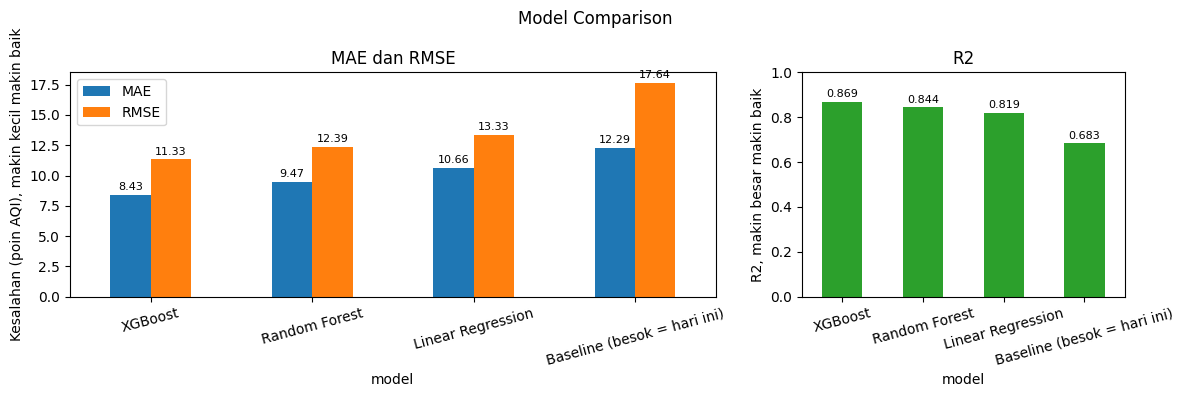

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw={'width_ratios': [2, 1]})

# Kiri: MAE dan RMSE
metrik[['MAE', 'RMSE']].plot(kind='bar', ax=axes[0], rot=15)
axes[0].set_ylabel("Kesalahan (poin AQI), makin kecil makin baik")
axes[0].set_title("MAE dan RMSE")
for c in axes[0].containers:
    axes[0].bar_label(c, fmt='%.2f', fontsize=8, padding=2)

# Kanan: R2
metrik[['R2']].plot(kind='bar', ax=axes[1], rot=15, color='tab:green', legend=False)
axes[1].set_ylabel("R2, makin besar makin baik")
axes[1].set_title("R2")
axes[1].set_ylim(0, 1)
for c in axes[1].containers:
    axes[1].bar_label(c, fmt='%.3f', fontsize=8, padding=2)

plt.suptitle("Model Comparison")
plt.tight_layout()
plt.show()

## 17. Cek Overfitting

In [ ]:
# Versi yang menerima prediksi langsung, bukan objek model
def skor(pred_latih, pred_uji):
    return {
        'MAE latih': round(mean_absolute_error(y_train, pred_latih), 2),
        'MAE uji':   round(mean_absolute_error(y_test,  pred_uji), 2),
        'R2 latih':  round(r2_score(y_train, pred_latih), 3),
        'R2 uji':    round(r2_score(y_test,  pred_uji), 3),
    }

cek = pd.DataFrame({
    # Baseline: tebakan "besok = hari ini", tanpa model dan tanpa proses belajar
    'Baseline (besok = hari ini)': skor(X_train['us_aqi'], X_test['us_aqi']),
    'Linear Regression': skor(lr.predict(X_train_s),  lr.predict(X_test_s)),
    'Random Forest':     skor(rf.predict(X_train),    rf.predict(X_test)),
    'XGBoost':           skor(xgb.predict(X_train),   xgb.predict(X_test)),
}).T

cek['selisih MAE'] = (cek['MAE uji'] - cek['MAE latih']).round(2)
cek['MAE uji vs baseline'] = (cek['MAE uji'] - cek.loc['Baseline (besok = hari ini)', 'MAE uji']).round(2)
print(cek)

                             MAE latih  MAE uji  R2 latih  R2 uji  \
Baseline (besok = hari ini)      13.76    12.29     0.713   0.683   
Linear Regression                11.13    10.66     0.840   0.819   
Random Forest                     3.50     9.47     0.983   0.844   
XGBoost                           3.75     8.43     0.981   0.869   

                             selisih MAE  MAE uji vs baseline  
Baseline (besok = hari ini)        -1.47                 0.00  
Linear Regression                  -0.47                -1.63  
Random Forest                       5.97                -2.82  
XGBoost                             4.68                -3.86  


## 18. Tuning dengan GridSearchCV

Memakai `TimeSeriesSplit` (bukan `cv=5` biasa yang mengacak waktu), dan hanya pada data latih.

In [ ]:
param_grid = {
    'n_estimators':  [100, 300],
    'learning_rate': [0.03, 0.05, 0.1],
    'max_depth':     [3, 4, 5],
    'subsample':     [0.8, 1.0],
}

grid = GridSearchCV(
    XGBRegressor(random_state=42, n_jobs=-1),
    param_grid,
    cv=TimeSeriesSplit(n_splits=5),
    scoring='neg_mean_absolute_error',
    n_jobs=-1,
    verbose=1,
)
grid.fit(X_train, y_train)

print("Parameter terbaik:", grid.best_params_)
print("MAE validasi (rata-rata lipatan):", round(-grid.best_score_, 2))

Fitting 5 folds for each of 36 candidates, totalling 180 fits
Parameter terbaik: {'learning_rate': 0.05, 'max_depth': 4, 'n_estimators': 100, 'subsample': 0.8}
MAE validasi (rata-rata lipatan): 9.71


In [ ]:
cv = pd.DataFrame(grid.cv_results_)
top = cv[['param_learning_rate', 'param_max_depth', 'param_n_estimators',
          'param_subsample', 'mean_test_score', 'std_test_score']].copy()
top['MAE_valid'] = -top['mean_test_score']
print(top.sort_values('MAE_valid').head(8).round(3).to_string(index=False))

 param_learning_rate  param_max_depth  param_n_estimators  param_subsample  mean_test_score  std_test_score  MAE_valid
                0.05                4                 100              0.8           -9.714           0.792      9.714
                0.05                3                 100              0.8           -9.763           0.785      9.763
                0.05                4                 300              0.8           -9.763           0.739      9.763
                0.10                5                 100              0.8           -9.830           0.794      9.830
                0.10                5                 300              0.8           -9.845           0.779      9.845
                0.05                5                 100              0.8           -9.865           0.911      9.865
                0.03                5                 300              0.8           -9.895           0.989      9.895
                0.05                5           

Delapan kombinasi teratas berbeda sangat tipis dibanding simpangan antar lipatan, jadi tuning tidak menemukan pemenang yang jelas. Dua kandidat dibandingkan: juara grid dan versi sederhana (kedalaman 3).

In [ ]:
xgb_juara_grid = grid.best_estimator_   # sudah dilatih ulang pada seluruh X_train

xgb_sederhana = XGBRegressor(learning_rate=0.05, max_depth=3, n_estimators=100,
                             subsample=0.8, random_state=42, n_jobs=-1)
xgb_sederhana.fit(X_train, y_train)
print("xgb_juara_grid dan xgb_sederhana siap")

xgb_juara_grid dan xgb_sederhana siap


In [ ]:
cek2 = pd.DataFrame({
    'Baseline (besok = hari ini)': skor(X_train['us_aqi'], X_test['us_aqi']),
    'XGBoost sebelum tuning':      skor(xgb.predict(X_train),              xgb.predict(X_test)),
    'XGBoost juara grid':          skor(xgb_juara_grid.predict(X_train),   xgb_juara_grid.predict(X_test)),
    'XGBoost sederhana (depth 3)': skor(xgb_sederhana.predict(X_train),    xgb_sederhana.predict(X_test)),
}).T
cek2['selisih MAE'] = (cek2['MAE uji'] - cek2['MAE latih']).round(2)
print(cek2)

                             MAE latih  MAE uji  R2 latih  R2 uji  selisih MAE
Baseline (besok = hari ini)      13.76    12.29     0.713   0.683        -1.47
XGBoost sebelum tuning            3.75     8.43     0.981   0.869         4.68
XGBoost juara grid                6.31     8.78     0.947   0.867         2.47
XGBoost sederhana (depth 3)       7.64     8.83     0.922   0.862         1.19


## 19. Validasi Kandidat dengan Lipatan Waktu

Pemilihan model final sebaiknya tidak bergantung pada data uji. Di sini ketiga kandidat dibandingkan hanya dengan data latih lewat `TimeSeriesSplit`. Bila rata-rata MAE berselisih kurang dari simpangannya, kandidatnya setara dan dipilih yang paling sederhana.

In [ ]:
tscv = TimeSeriesSplit(n_splits=5)

kandidat = {
    'XGBoost awal (depth 4, 300 pohon)': XGBRegressor(n_estimators=300, learning_rate=0.05,
                                                      max_depth=4, random_state=42, n_jobs=-1),
    f"XGBoost juara grid (depth {grid.best_params_['max_depth']})": xgb_juara_grid,
    'XGBoost sederhana (depth 3)':       XGBRegressor(learning_rate=0.05, max_depth=3, n_estimators=100,
                                                      subsample=0.8, random_state=42, n_jobs=-1),
}

for nama, m in kandidat.items():
    skor_cv = -cross_val_score(m, X_train, y_train, cv=tscv,
                               scoring='neg_mean_absolute_error')
    print(f"{nama:36s} MAE per lipatan: {skor_cv.round(2)} | "
          f"rata-rata {skor_cv.mean():.2f} | simpangan {skor_cv.std():.2f}")

XGBoost awal (depth 4, 300 pohon)    MAE per lipatan: [11.64  9.1  10.14  9.17 10.82] | rata-rata 10.18 | simpangan 0.97
XGBoost juara grid (depth 4)         MAE per lipatan: [10.67  8.82  9.89  8.77 10.42] | rata-rata 9.71 | simpangan 0.79
XGBoost sederhana (depth 3)          MAE per lipatan: [10.23  8.85  9.73  9.02 10.98] | rata-rata 9.76 | simpangan 0.78


## 20. Model Final: XGBoost Kedalaman 3

Dipilih karena paling stabil (selisih MAE latih dan uji paling kecil) dengan akurasi uji yang setara kandidat lain. Model dilatih hanya pada data latih; `best_xgb` didefinisikan **satu kali** di sini.

In [ ]:
best_xgb = XGBRegressor(
    n_estimators=100,
    learning_rate=0.05,
    max_depth=3,
    subsample=0.8,
    random_state=42,
    n_jobs=-1,
)
best_xgb.fit(X_train, y_train)

pred_latih = best_xgb.predict(X_train)
pred_uji   = best_xgb.predict(X_test)

hasil_final = pd.DataFrame([
    evaluasi('Baseline (data uji)',          y_test,  X_test['us_aqi']),
    evaluasi('XGBoost depth 3 (data latih)', y_train, pred_latih),
    evaluasi('XGBoost depth 3 (data uji)',   y_test,  pred_uji),
]).set_index('model')

print(hasil_final)
print("selisih MAE uji - latih:",
      round(mean_absolute_error(y_test, pred_uji) - mean_absolute_error(y_train, pred_latih), 2))

                                MAE   RMSE     R2
model                                            
Baseline (data uji)           12.29  17.64  0.683
XGBoost depth 3 (data latih)   7.64   9.94  0.922
XGBoost depth 3 (data uji)     8.83  11.63  0.862
selisih MAE uji - latih: 1.2


## 21. Feature Importance (Model Final)

Dihitung pada `best_xgb` (model yang disimpan), bukan pada model awal.

                       XGBoost final  Random Forest
pm2_5                          0.535          0.795
pm10                           0.141          0.083
ozone                          0.060          0.013
aerosol_optical_depth          0.038          0.008
sulphur_dioxide                0.024          0.011
aqi_lag3                       0.020          0.006
carbon_monoxide                0.019          0.008
aqi_rata7                      0.017          0.005
us_aqi                         0.015          0.013
nitrogen_dioxide               0.015          0.008
aqi_lag7                       0.014          0.005
pm25_lag7                      0.014          0.005
bulan_cos                      0.013          0.003
aqi_lag2                       0.013          0.005
uv_index                       0.011          0.007
pm25_lag1                      0.011          0.006
pm25_lag2                      0.011          0.005
aqi_lag1                       0.010          0.005
pm25_lag3   

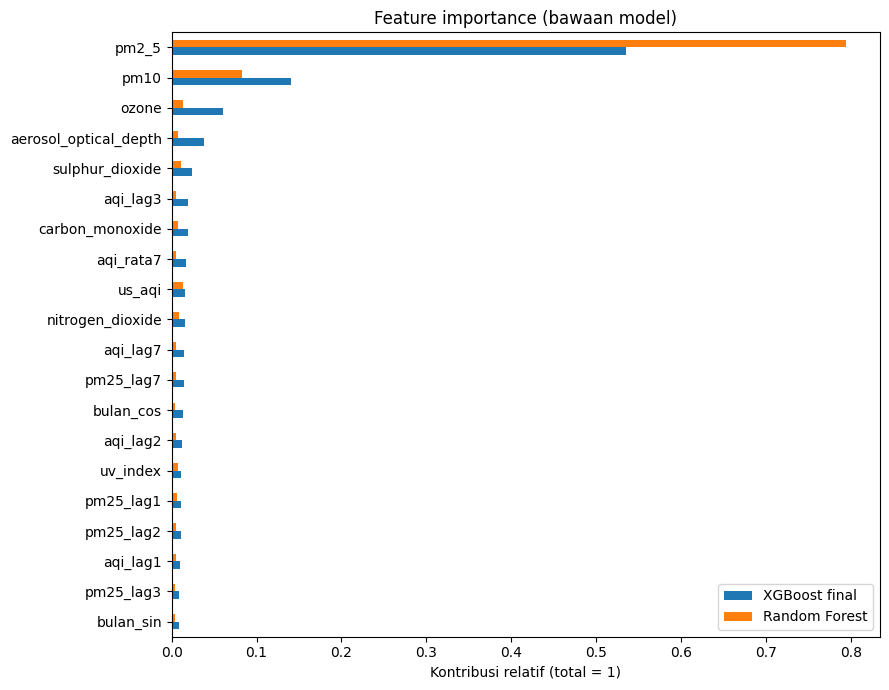

In [ ]:
imp = pd.DataFrame({
    'XGBoost final': best_xgb.feature_importances_,
    'Random Forest': rf.feature_importances_,
}, index=X_train.columns).sort_values('XGBoost final', ascending=False)

print(imp.round(3))

imp.sort_values('XGBoost final').plot(kind='barh', figsize=(9, 7))
plt.title("Feature importance (bawaan model)")
plt.xlabel("Kontribusi relatif (total = 1)")
plt.tight_layout()
plt.show()

                       naik MAE (poin AQI)  simpangan
pm2_5                               12.669      0.867
pm10                                 2.310      0.197
ozone                                1.089      0.216
carbon_monoxide                      0.824      0.227
us_aqi                               0.642      0.176
nitrogen_dioxide                     0.622      0.113
pm25_lag1                            0.084      0.047
pm25_lag7                            0.050      0.062
aerosol_optical_depth                0.044      0.037
pm25_lag2                            0.014      0.011
aqi_lag2                             0.012      0.015
uv_index                             0.012      0.026
aqi_lag1                             0.010      0.033
bulan_cos                            0.004      0.043
sulphur_dioxide                     -0.001      0.019
pm25_lag3                           -0.004      0.023
aqi_lag3                            -0.006      0.046
aqi_lag7                    

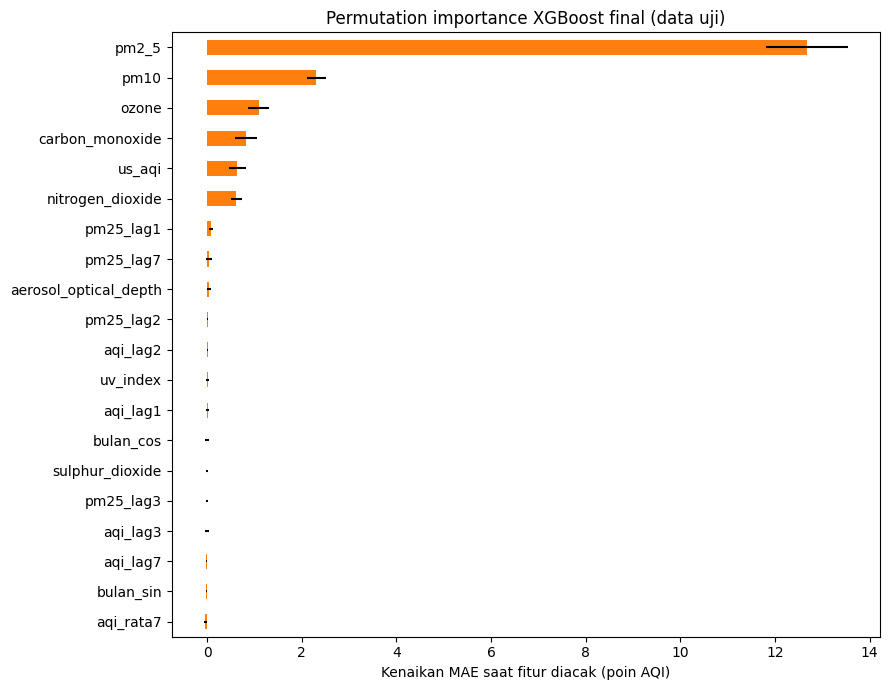

In [ ]:
hasil_perm = permutation_importance(
    best_xgb, X_test, y_test, n_repeats=20, random_state=42,
    scoring='neg_mean_absolute_error'
)

perm = pd.DataFrame({
    'naik MAE (poin AQI)': hasil_perm.importances_mean,
    'simpangan':           hasil_perm.importances_std,
}, index=X_test.columns).sort_values('naik MAE (poin AQI)', ascending=False)

print(perm.round(3))

urut = perm['naik MAE (poin AQI)'].sort_values().index
perm.loc[urut, 'naik MAE (poin AQI)'].plot(
    kind='barh', xerr=perm.loc[urut, 'simpangan'],
    figsize=(9, 7), color='tab:orange')
plt.title("Permutation importance XGBoost final (data uji)")
plt.xlabel("Kenaikan MAE saat fitur diacak (poin AQI)")
plt.tight_layout()
plt.show()

sulphur_dioxide          17.72
aqi_lag1                 13.77
pm25_lag1               -13.50
pm2_5                    11.38
nitrogen_dioxide         11.08
ozone                    10.63
bulan_sin                -8.14
bulan_cos                -4.16
uv_index                  3.65
us_aqi                    3.02
aerosol_optical_depth     2.93
carbon_monoxide           2.01
aqi_lag3                  1.95
aqi_lag2                 -1.38
aqi_rata7                -1.38
pm25_lag2                -1.25
pm10                      0.94
pm25_lag7                 0.87
aqi_lag7                  0.54
pm25_lag3                -0.01
dtype: float64


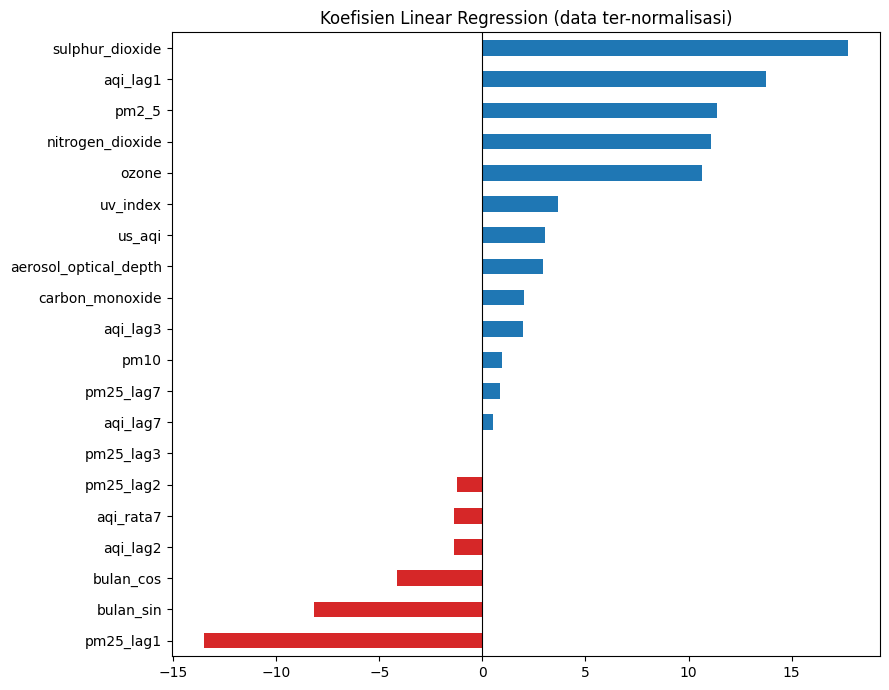

In [ ]:
koef = pd.Series(lr.coef_, index=X_train.columns)
koef = koef.reindex(koef.abs().sort_values(ascending=False).index)
print(koef.round(2))

koef.sort_values().plot(kind='barh', figsize=(9, 7),
                        color=['tab:red' if v < 0 else 'tab:blue' for v in koef.sort_values()])
plt.title("Koefisien Linear Regression (data ter-normalisasi)")
plt.axvline(0, color='black', lw=0.8)
plt.tight_layout()
plt.show()

PM2.5 (hari ini + riwayat)    0.580
pm10                          0.141
AQI (hari ini + riwayat)      0.089
ozone                         0.060
aerosol_optical_depth         0.038
sulphur_dioxide               0.024
Musim (bulan)                 0.022
carbon_monoxide               0.019
nitrogen_dioxide              0.015
uv_index                      0.011
Name: XGBoost final, dtype: float32


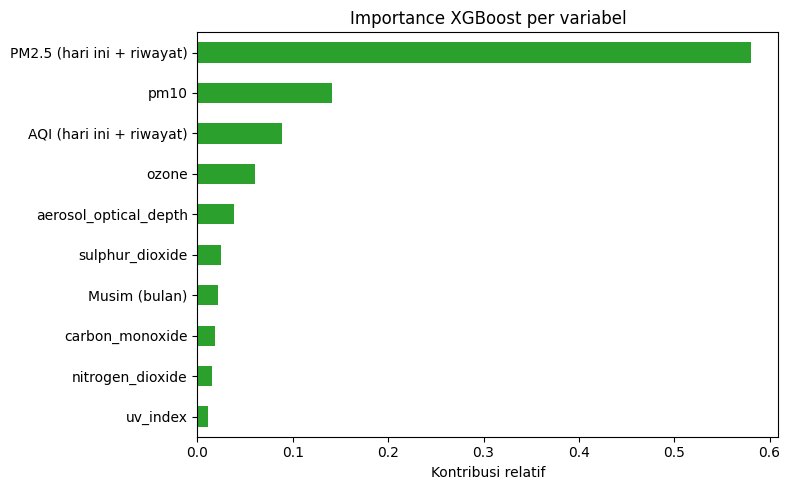

In [ ]:
def kelompok(nama):
    if nama in ['us_aqi', 'aqi_rata7'] or nama.startswith('aqi_lag'):
        return 'AQI (hari ini + riwayat)'
    if nama == 'pm2_5' or nama.startswith('pm25_lag'):
        return 'PM2.5 (hari ini + riwayat)'
    if nama.startswith('bulan_'):
        return 'Musim (bulan)'
    return nama

grup = imp['XGBoost final'].groupby(kelompok).sum().sort_values(ascending=True)
print(grup.round(3).sort_values(ascending=False))

grup.plot(kind='barh', figsize=(8, 5), color='tab:green')
plt.title("Importance XGBoost per variabel")
plt.xlabel("Kontribusi relatif")
plt.tight_layout()
plt.show()

## 22. Simpan Model dan Daftar Kolom Fitur

Urutan kolom fitur wajib sama persis saat memprediksi (misalnya di FastAPI), jadi disimpan bersama model.

In [ ]:
from google.colab import files

# Model
joblib.dump(best_xgb, "model_aqi_jakarta.pkl")

# Daftar dan urutan kolom fitur (wajib sama persis saat memprediksi nanti)
with open("kolom_fitur.json", "w") as f:
    json.dump(list(X_train.columns), f)

files.download("model_aqi_jakarta.pkl")
files.download("kolom_fitur.json")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
model_muat = joblib.load("model_aqi_jakarta.pkl")
with open("kolom_fitur.json") as f:
    kolom_fitur = json.load(f)

print("kolom sama:", kolom_fitur == list(X_train.columns))
print("prediksi sama:", np.allclose(model_muat.predict(X_test[kolom_fitur]), best_xgb.predict(X_test)))

kolom sama: True
prediksi sama: True


## 23. Prediksi AQI Besok

Model butuh riwayat minimal 7 hari karena fiturnya memakai lag 7 hari dan rata-rata 7 hari. Fungsi `buat_fitur` harus identik dengan yang dipakai saat latihan (diverifikasi terhadap `X`).

In [ ]:
def buat_fitur(d):
    f = d.copy()
    for lag in [1, 2, 3, 7]:
        f[f'aqi_lag{lag}']  = f['us_aqi'].shift(lag)
        f[f'pm25_lag{lag}'] = f['pm2_5'].shift(lag)
    f['aqi_rata7'] = f['us_aqi'].rolling(7).mean()
    bulan = f.index.month
    f['bulan_sin'] = np.sin(2 * np.pi * bulan / 12)
    f['bulan_cos'] = np.cos(2 * np.pi * bulan / 12)
    return f[kolom_fitur]          # urutan kolom dari file kolom_fitur.json

fitur_semua = buat_fitur(aq)

# Validasi: hasilnya harus sama dengan X yang dipakai saat latihan
print("sama dengan X:", np.allclose(fitur_semua.loc[X.index], X))

sama dengan X: True


In [ ]:
baris_terakhir = fitur_semua.iloc[[-1]]
assert not baris_terakhir.isna().any().any(), "ada fitur kosong, riwayat kurang dari 7 hari"

pred_besok = model_muat.predict(baris_terakhir)[0]
tgl_target = baris_terakhir.index[0] + pd.Timedelta(days=1)

def kategori(aqi):
    if aqi <= 50:  return "Baik"
    if aqi <= 100: return "Sedang"
    if aqi <= 150: return "Tidak sehat untuk kelompok sensitif"
    if aqi <= 200: return "Tidak sehat"
    if aqi <= 300: return "Sangat tidak sehat"
    return "Berbahaya"

print(f"Fitur dari   : {baris_terakhir.index[0].date()}")
print(f"Prediksi AQI : {tgl_target.date()} = {pred_besok:.1f}  ({kategori(pred_besok)})")

Fitur dari   : 2026-02-18
Prediksi AQI : 2026-02-19 = 144.8  (Tidak sehat untuk kelompok sensitif)


## 24. Simpan Prediksi ke CSV

In [ ]:
pred_uji = model_muat.predict(X_test[kolom_fitur])

hasil_uji = pd.DataFrame({
    'tanggal_fitur':  X_test.index,
    'tanggal_target': X_test.index + pd.Timedelta(days=1),
    'aqi_aktual':     y_test.values.round(2),
    'aqi_prediksi':   pred_uji.round(2),
})
hasil_uji['selisih']        = (hasil_uji['aqi_prediksi'] - hasil_uji['aqi_aktual']).round(2)
hasil_uji['kategori_aktual']   = hasil_uji['aqi_aktual'].map(kategori)
hasil_uji['kategori_prediksi'] = hasil_uji['aqi_prediksi'].map(kategori)

hasil_uji.to_csv("prediksi_aqi_jakarta.csv", index=False)
files.download("prediksi_aqi_jakarta.csv")

print(hasil_uji.shape)
print("MAE dari CSV:", hasil_uji['selisih'].abs().mean().round(2))   # harus sekitar 8.88
hasil_uji.head()

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

(258, 7)
MAE dari CSV: 8.83


,tanggal_fitur,tanggal_target,aqi_aktual,aqi_prediksi,selisih,kategori_aktual,kategori_prediksi
0,2025-06-05,2025-06-06,186.92,181.320007,-5.60,Tidak sehat,Tidak sehat
1,2025-06-06,2025-06-07,168.33,176.160004,7.83,Tidak sehat,Tidak sehat
2,2025-06-07,2025-06-08,175.62,173.460007,-2.16,Tidak sehat,Tidak sehat
3,2025-06-08,2025-06-09,184.00,174.289993,-9.71,Tidak sehat,Tidak sehat
4,2025-06-09,2025-06-10,190.88,180.389999,-10.49,Tidak sehat,Tidak sehat


## 25. Plot Aktual vs Prediksi

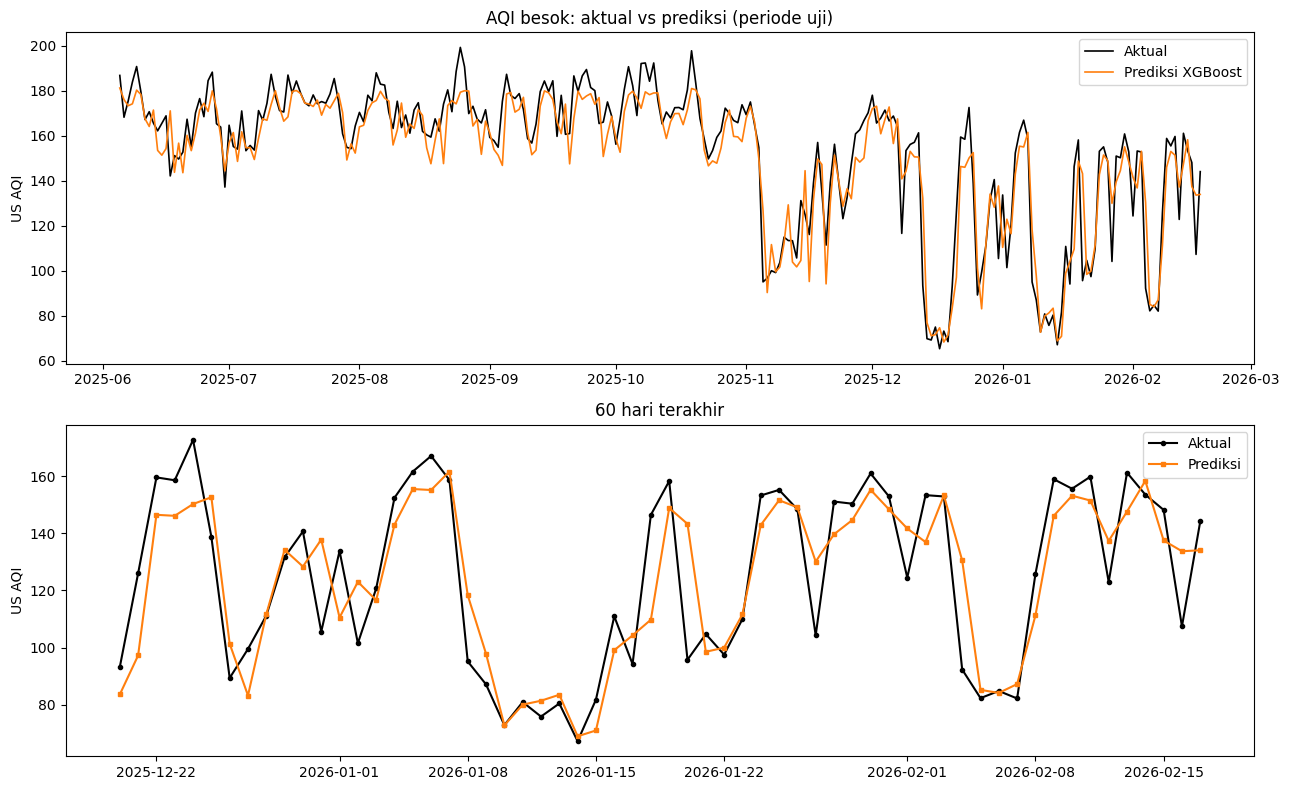

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
fig, axes = plt.subplots(2, 1, figsize=(13, 8))

# Seluruh periode uji
axes[0].plot(y_test.index, y_test.values, label='Aktual', color='black', lw=1.2)
axes[0].plot(y_test.index, pred_uji, label='Prediksi XGBoost', color='tab:orange', lw=1.2)
axes[0].set_title("AQI besok: aktual vs prediksi (periode uji)")
axes[0].set_ylabel("US AQI")
axes[0].legend()

# 60 hari terakhir supaya selisih terlihat jelas
n = 60
axes[1].plot(y_test.index[-n:], y_test.values[-n:], label='Aktual', color='black', marker='o', ms=3)
axes[1].plot(y_test.index[-n:], pred_uji[-n:], label='Prediksi', color='tab:orange', marker='s', ms=3)
axes[1].set_title(f"{n} hari terakhir")
axes[1].set_ylabel("US AQI")
axes[1].legend()

plt.tight_layout()
plt.savefig("aktual_vs_prediksi.png", dpi=150)
plt.show()
files.download("aktual_vs_prediksi.png")

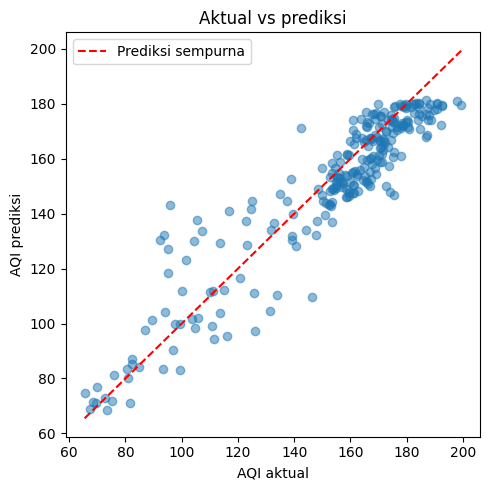

In [ ]:
# Scatter: makin dekat ke garis merah, makin akurat
plt.figure(figsize=(5, 5))
plt.scatter(y_test, pred_uji, alpha=0.5)
lo, hi = y_test.min(), y_test.max()
plt.plot([lo, hi], [lo, hi], 'r--', label='Prediksi sempurna')
plt.xlabel("AQI aktual")
plt.ylabel("AQI prediksi")
plt.title("Aktual vs prediksi")
plt.legend()
plt.tight_layout()
plt.show()

## 26. Analisis Kesalahan

Di mana model meleset paling jauh, dan apakah model hanya mengikuti AQI hari ini?

In [ ]:
hasil_uji['abs_selisih'] = hasil_uji['selisih'].abs()

# 1. Sepuluh hari dengan meleset terbesar
print(hasil_uji.sort_values('abs_selisih', ascending=False)
      .head(10)[['tanggal_target', 'aqi_aktual', 'aqi_prediksi', 'selisih']])

# 2. Error rata-rata per rentang AQI aktual
hasil_uji['rentang'] = pd.cut(hasil_uji['aqi_aktual'], [0, 100, 150, 175, 250])
print(hasil_uji.groupby('rentang', observed=True)['abs_selisih']
      .agg(['count', 'mean']).round(2))

# 3. Apakah prediksi hanya mengikuti AQI hari ini?
print("korelasi prediksi vs AQI hari ini:", np.corrcoef(pred_uji, X_test['us_aqi'])[0, 1].round(3))
print("korelasi prediksi vs AQI aktual  :", np.corrcoef(pred_uji, y_test)[0, 1].round(3))

    tanggal_target  aqi_aktual  aqi_prediksi  selisih
229     2026-01-21       95.71    143.259995    47.55
191     2025-12-14       93.54    132.360001    38.82
244     2026-02-05       92.29    130.460007    38.17
227     2026-01-19      146.42    109.739998   -36.68
209     2026-01-01      105.54    137.800003    32.26
153     2025-11-06       95.17    126.970001    31.80
12      2025-06-18      142.25    171.169998    28.92
199     2025-12-22      125.96     97.220001   -28.74
91      2025-09-05      175.38    146.929993   -28.45
162     2025-11-15      131.29    104.690002   -26.60
            count   mean
rentang                 
(0, 100]       28  10.98
(100, 150]     43  13.24
(150, 175]    128   7.13
(175, 250]     59   8.30
korelasi prediksi vs AQI hari ini: 0.939
korelasi prediksi vs AQI aktual  : 0.934


In [ ]:
# Apakah model menebak ARAH perubahan AQI dari hari ini ke besok?
hari_ini      = X_test['us_aqi'].values
ubah_aktual   = hasil_uji['aqi_aktual'].values   - hari_ini
ubah_prediksi = hasil_uji['aqi_prediksi'].values - hari_ini

besar = np.abs(ubah_aktual) >= 20      # hari dengan perubahan besar

print("korelasi perubahan aktual vs prediksi:",
      np.corrcoef(ubah_aktual, ubah_prediksi)[0, 1].round(3))
print("hari dengan perubahan >= 20 poin     :", besar.sum(), "dari", len(besar))
print("arah benar (semua hari)              :",
      (np.sign(ubah_aktual) == np.sign(ubah_prediksi)).mean().round(3))
print("arah benar (perubahan besar)         :",
      (np.sign(ubah_aktual[besar]) == np.sign(ubah_prediksi[besar])).mean().round(3))

# Error rata-rata per bulan
hasil_uji['bulan'] = pd.to_datetime(hasil_uji['tanggal_target']).dt.month
print(hasil_uji.groupby('bulan')['abs_selisih'].agg(['count', 'mean']).round(2))

korelasi perubahan aktual vs prediksi: 0.791
hari dengan perubahan >= 20 poin     : 45 dari 258
arah benar (semua hari)              : 0.717
arah benar (perubahan besar)         : 0.933
       count   mean
bulan              
1         31  11.51
2         18  11.30
6         25   8.05
7         31   5.13
8         31   8.58
9         30   8.41
10        31   7.18
11        30  10.06
12        31  10.19


## 27. Kesimpulan dan Keterbatasan

**Hasil.** Model final (XGBoost kedalaman 3) memprediksi US AQI besok dengan MAE uji sekitar 8,8 poin dan R² sekitar 0,86, dibanding baseline "besok = hari ini" dengan MAE 12,29 dan R² 0,683 (perbaikan MAE sekitar 28%). Ketiga model mengalahkan baseline; urutannya XGBoost, Random Forest, lalu Linear Regression. Angka persisnya dapat bergeser sekitar 0,1 poin antar versi pustaka, jadi pakai angka dari tabel di langkah 20.

**Overfitting.** Selisih MAE latih dan uji pada model final hanya sekitar 1,2 poin, jauh lebih kecil daripada model awal (sekitar 4,7). Tuning tidak menurunkan MAE uji; delapan kombinasi teratas hanya berbeda sekitar 0,2 poin pada validasi, jadi dipilih konfigurasi paling sederhana.

**Fitur.** PM2.5 paling berpengaruh (mengacaknya menaikkan MAE sekitar 12,7 poin), diikuti PM10 dan ozon. Fitur lag dan rata-rata 7 hari menyumbang sangat sedikit setelah polutan hari ini diketahui.

**Kesalahan.** Error terbesar ada pada rentang AQI aktual 101 sampai 150 (MAE sekitar 13) dan pada bulan November sampai Februari (musim hujan, MAE sekitar 10 sampai 11.5, dibanding sekitar 5 sampai 8.6 pada Juni sampai Oktober). Arah perubahan AQI yang besar (20 poin atau lebih) ditebak benar pada sekitar 93% harinya (45 hari); yang meleset terutama **besarnya** perubahan, bukan arahnya.

**Keterbatasan.**
- Data berasal dari model CAMS (Open-Meteo), bukan sensor stasiun.
- Dua hari (2022-12-14 dan 12-15) bernilai tidak wajar dan diimputasi dengan interpolasi, jadi bukan data nyata.
- Hanya satu split uji (258 hari, Juni 2025 sampai Februari 2026); periode Maret sampai Mei tidak ada di data uji.
- Model butuh riwayat minimal 7 hari, dan belum memakai data cuaca (hujan, angin) yang kemungkinan membantu memprediksi penurunan mendadak.

- MULTI KOTA

In [ ]:
import time
import requests

KOTA = [
    {"id": "jakarta",    "lat": -6.2146, "lon": 106.8451, "tz": "Asia/Jakarta"},
    {"id": "bandung",    "lat": -6.9175, "lon": 107.6191, "tz": "Asia/Jakarta"},
    {"id": "semarang",   "lat": -6.9667, "lon": 110.4167, "tz": "Asia/Jakarta"},
    {"id": "yogyakarta", "lat": -7.7956, "lon": 110.3695, "tz": "Asia/Jakarta"},
    {"id": "surabaya",   "lat": -7.2575, "lon": 112.7521, "tz": "Asia/Jakarta"},
    {"id": "medan",      "lat": 3.5952,  "lon": 98.6722,  "tz": "Asia/Jakarta"},
    {"id": "palembang",  "lat": -2.9761, "lon": 104.7754, "tz": "Asia/Jakarta"},
    {"id": "pontianak",  "lat": -0.0263, "lon": 109.3425, "tz": "Asia/Jakarta"},
    {"id": "balikpapan", "lat": -1.2379, "lon": 116.8529, "tz": "Asia/Makassar"},
    {"id": "makassar",   "lat": -5.1477, "lon": 119.4327, "tz": "Asia/Makassar"},
    {"id": "denpasar",   "lat": -8.6705, "lon": 115.2126, "tz": "Asia/Makassar"},
    {"id": "jayapura",   "lat": -2.5337, "lon": 140.7181, "tz": "Asia/Jayapura"},
]

URL_AQ = "https://air-quality-api.open-meteo.com/v1/air-quality"
KOLOM_DASAR = ["pm10", "pm2_5", "carbon_monoxide", "nitrogen_dioxide", "sulphur_dioxide",
               "ozone", "aerosol_optical_depth", "uv_index", "us_aqi"]

def unduh_kota(k, mulai="2022-08-01"):
    """Data per jam sampai kemarin (waktu lokal kota), domain cams_global seperti dataset Kaggle."""
    kemarin = (pd.Timestamp.now(tz=k["tz"]).normalize() - pd.Timedelta(days=1)).strftime("%Y-%m-%d")
    for percobaan in range(3):
        r = requests.get(URL_AQ, params={
            "latitude": k["lat"], "longitude": k["lon"],
            "hourly": ",".join(KOLOM_DASAR), "domains": "cams_global",
            "timezone": k["tz"], "start_date": mulai, "end_date": kemarin,
        }, timeout=120)
        if r.status_code == 200:
            return r.json()["hourly"]
        time.sleep(5 * (percobaan + 1))
    r.raise_for_status()

In [ ]:
KOLOM_FITUR = ['pm10', 'pm2_5', 'carbon_monoxide', 'nitrogen_dioxide', 'sulphur_dioxide',
               'ozone', 'aerosol_optical_depth', 'uv_index', 'us_aqi',
               'aqi_lag1', 'pm25_lag1', 'aqi_lag2', 'pm25_lag2', 'aqi_lag3', 'pm25_lag3',
               'aqi_lag7', 'pm25_lag7', 'aqi_rata7', 'bulan_sin', 'bulan_cos']

def agregasi_harian(hourly, jam_minimum=20):
    df = pd.DataFrame(hourly)
    df["time"] = pd.to_datetime(df["time"])
    df = df.set_index("time").apply(pd.to_numeric, errors="coerce")
    harian = df.resample("D").mean()
    jam_valid = df["us_aqi"].resample("D").count()
    harian = harian[jam_valid >= jam_minimum]          # buang hari yang datanya bolong
    harian.index.name = "date"
    return harian

def buat_fitur(d, kolom_fitur):
    f = d.copy()
    for lag in [1, 2, 3, 7]:
        f[f"aqi_lag{lag}"] = f["us_aqi"].shift(lag)
        f[f"pm25_lag{lag}"] = f["pm2_5"].shift(lag)
    f["aqi_rata7"] = f["us_aqi"].rolling(7).mean()
    bulan = f.index.month
    f["bulan_sin"] = np.sin(2 * np.pi * bulan / 12)
    f["bulan_cos"] = np.cos(2 * np.pi * bulan / 12)
    return f[kolom_fitur]

In [ ]:
BATAS_LATIH = pd.Timestamp("2025-06-04")    # sama dengan split di notebook Jakarta

frames = []
for k in KOTA:
    harian = agregasi_harian(unduh_kota(k))
    time.sleep(1)                           # sopan terhadap server gratis

    # hari tanpa data jangan "dijembatani": reindex agar lag tidak salah rujuk
    harian = harian.reindex(pd.date_range(harian.index.min(), harian.index.max(), freq="D"))
    harian.index.name = "date"

    # artefak seperti 2022-12-14/15 di Jakarta (NO2 = 0 dan CO anjlok): kosongkan lalu interpolasi
    anomali = (harian["nitrogen_dioxide"] <= 0.5) & (harian["carbon_monoxide"] < 200)
    harian.loc[anomali, KOLOM_DASAR] = np.nan
    harian[KOLOM_DASAR] = harian[KOLOM_DASAR].interpolate(method="time", limit=3)

    f = buat_fitur(harian[KOLOM_DASAR], KOLOM_FITUR)
    f["target"] = harian["us_aqi"].shift(-1)
    f = f.dropna()
    f["kota"] = k["id"]
    frames.append(f)
    print(f"{k['id']:11s} hari: {len(f):5d} | {f.index.min().date()} s/d {f.index.max().date()} | anomali diperbaiki: {int(anomali.sum())}")

semua = pd.concat(frames)
print("total baris:", semua.shape)

jakarta     hari:  1546 | 2022-08-13 s/d 2026-11-05 | anomali diperbaiki: 2
bandung     hari:  1546 | 2022-08-13 s/d 2026-11-05 | anomali diperbaiki: 2
semarang    hari:  1546 | 2022-08-13 s/d 2026-11-05 | anomali diperbaiki: 2
yogyakarta  hari:  1546 | 2022-08-13 s/d 2026-11-05 | anomali diperbaiki: 2
surabaya    hari:  1546 | 2022-08-13 s/d 2026-11-05 | anomali diperbaiki: 2
medan       hari:  1546 | 2022-08-13 s/d 2026-11-05 | anomali diperbaiki: 2
palembang   hari:  1546 | 2022-08-13 s/d 2026-11-05 | anomali diperbaiki: 2
pontianak   hari:  1546 | 2022-08-13 s/d 2026-11-05 | anomali diperbaiki: 2
balikpapan  hari:  1546 | 2022-08-13 s/d 2026-11-05 | anomali diperbaiki: 2
makassar    hari:  1546 | 2022-08-13 s/d 2026-11-05 | anomali diperbaiki: 2
denpasar    hari:  1546 | 2022-08-13 s/d 2026-11-05 | anomali diperbaiki: 2
jayapura    hari:  1546 | 2022-08-13 s/d 2026-11-05 | anomali diperbaiki: 2
total baris: (18552, 22)


In [ ]:
train = semua[semua.index <= BATAS_LATIH]
test  = semua[semua.index >  BATAS_LATIH]
print("train:", train.shape, "| test:", test.shape, "| periode uji:", test.index.min().date(), "s/d", test.index.max().date())

def buat_model():
    return XGBRegressor(n_estimators=100, learning_rate=0.05, max_depth=3,
                        subsample=0.8, random_state=42, n_jobs=-1)

model = buat_model().fit(train[KOLOM_FITUR], train["target"])

baris = []
for k in KOTA:
    cid = k["id"]
    te = test[test["kota"] == cid]
    if len(te) < 30:
        print("lewati", cid, "(data uji terlalu sedikit)"); continue
    pred = model.predict(te[KOLOM_FITUR])

    tr_lain = train[train["kota"] != cid]
    m_lain = buat_model().fit(tr_lain[KOLOM_FITUR], tr_lain["target"])
    pred_lain = m_lain.predict(te[KOLOM_FITUR])

    baris.append({
        "kota": cid, "hari_uji": len(te),
        "mae_baseline":  mean_absolute_error(te["target"], te["us_aqi"]),
        "mae_model":     mean_absolute_error(te["target"], pred),
        "mae_kota_baru": mean_absolute_error(te["target"], pred_lain),
        "bias_model":    float(np.mean(pred - te["target"])),   # + = cenderung melebihkan
    })

hasil = pd.DataFrame(baris).set_index("kota")
hasil["perbaikan_%"]           = (1 - hasil["mae_model"]     / hasil["mae_baseline"]) * 100
hasil["perbaikan_kota_baru_%"] = (1 - hasil["mae_kota_baru"] / hasil["mae_baseline"]) * 100

SYARAT = 0.85      # lulus bila MAE model <= 85% MAE baseline (perbaikan minimal 15%)
hasil["tervalidasi"] = hasil["mae_model"] <= SYARAT * hasil["mae_baseline"]
print(hasil.round(2))

train: (12324, 22) | test: (6228, 22) | periode uji: 2025-06-05 s/d 2026-11-05
            hari_uji  mae_baseline  mae_model  mae_kota_baru  bias_model  \
kota                                                                       
jakarta          519         11.92       8.92          12.94       -2.99   
bandung          519          9.67       8.09           8.65       -3.98   
semarang         519         14.56      12.96          17.37       -2.51   
yogyakarta       519         22.43      14.47          15.04       -3.69   
surabaya         519         14.02      10.43          10.61        0.33   
medan            519         14.32       9.93          10.44       -0.58   
palembang        519          7.72       5.71           5.80       -1.21   
pontianak        519         11.37       8.43           8.59       -2.71   
balikpapan       519          5.69       3.73           3.85        0.65   
makassar         519          7.91       4.81           4.83       -0.51   
denpasar 

In [ ]:
import joblib, json
from google.colab import files

lulus = hasil.index[hasil["tervalidasi"]].tolist()
meta = {
    "versi": pd.Timestamp.now().strftime("%Y%m%d"),
    "file_model": "model_aqi.pkl",
    "kolom_fitur": KOLOM_FITUR,
    "kota_tervalidasi": lulus,
    "mae_uji": {c: round(float(hasil.loc[c, "mae_model"]), 2) for c in hasil.index},
    "mae_baseline": {c: round(float(hasil.loc[c, "mae_baseline"]), 2) for c in hasil.index},
    "dilatih_pada": f"{len(KOTA)} kota, data sampai {BATAS_LATIH.date()}, "
                    f"diuji {test.index.min().date()} s/d {test.index.max().date()}",
}
print("kota tervalidasi:", lulus)

joblib.dump(model, "model_aqi.pkl")
with open("meta.json", "w", encoding="utf-8") as f:
    json.dump(meta, f, indent=2, ensure_ascii=False)
hasil.round(2).to_csv("hasil_validasi_kota.csv")

for nama in ["model_aqi.pkl", "meta.json", "hasil_validasi_kota.csv"]:
    files.download(nama)

kota tervalidasi: ['jakarta', 'bandung', 'yogyakarta', 'surabaya', 'medan', 'palembang', 'pontianak', 'balikpapan', 'makassar', 'denpasar', 'jayapura']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import xgboost, sklearn; print(xgboost.__version__, sklearn.__version__)

3.4.1 1.6.1
